# 09 — Margens de segurança versus planejamento por reservas

Compara as decisões de quantidade resultantes das margens já calculadas no Notebook 06 com a contagem real de reservas, usando a coorte comum pareada definida pelo Notebook 07. Inclui margens fixas de 0, 5, 10, 15 e 20 refeições, além das margens prequential q50, q75 e q90; a regra de reservas é o baseline sem margem.

O objetivo é expor a escolha da gestão: cada cenário troca excesso potencial por falta potencial. Os pesos de falta:sobra (1:1, 2:1, 3:1 e 5:1) são apenas análises de sensibilidade, não custos observados. Nenhum cenário prova sobra física ou atendimento real.

In [1]:
from pathlib import Path
import os
import tempfile
import numpy as np
import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "mplconfig_novo_experimento"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd()
root_candidates = [cwd, cwd.parent, cwd / "NOVO_EXPERIMENTO"]
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não localizei a raiz F:/PRODUTO_MESTRADO.")
LINE_ID = "reservas_consumo_cardapio_calendario_clima"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
FEATURES_DIR = ROOT / "data" / "experimentos" / LINE_ID / "features"
assert ROOT is not None, f"Não localizei a raiz NOVO_EXPERIMENTO a partir de {cwd}."
OUT = LINE_RESULTS / "09_margens_vs_reservas"
OUT.mkdir(parents=True, exist_ok=True)
MARGINS_SOURCE = LINE_RESULTS / "06_margens_seguranca" / "previsoes_decisao_margens.csv"
PAIRED_SOURCE = LINE_RESULTS / "07_comparacao_reservas" / "previsoes_pareadas.csv"
for p in [MARGINS_SOURCE, PAIRED_SOURCE]:
    assert p.exists(), f"Fonte necessária ausente: {p}"

# O Notebook 07 define a coorte válida e os valores pareados modelo/reserva.
paired = pd.read_csv(PAIRED_SOURCE, encoding="utf-8-sig", parse_dates=["data"])
assert not paired.duplicated(["metodo", "data"]).any()
model_pairs = paired[paired["familia"] != "baseline_reservas"].copy()
reserve_pairs = paired[paired["familia"] == "baseline_reservas"].copy()
common_dates = set(reserve_pairs["data"])
methods = sorted(model_pairs["metodo"].unique())
assert common_dates and methods
assert model_pairs.groupby("metodo")["data"].nunique().eq(len(common_dates)).all()
assert reserve_pairs["data"].nunique() == len(common_dates)
assert model_pairs.groupby("metodo")["data"].nunique().eq(len(common_dates)).all()
print(f"Coorte do Notebook 07: {len(common_dates)} datas; {len(methods)} métodos; reservas incluídas nas mesmas datas.")


Coorte do Notebook 07: 390 datas; 65 métodos; reservas incluídas nas mesmas datas.


In [2]:
# Ler apenas colunas necessárias do arquivo grande de margens e manter uma razão,
# pois a quantidade decidida é a mesma para qualquer peso de penalidade.
usecols = [
    "fold", "origem", "data", "ano", "metodo", "consumo_real", "previsao",
    "politica_margem", "margem_refeicoes", "quantidade_simulada", "razao_penalidade_falta_sobra",
]
margin = pd.read_csv(MARGINS_SOURCE, usecols=usecols, encoding="utf-8-sig", low_memory=False)
margin["data"] = pd.to_datetime(margin["data"], format="mixed", errors="raise").dt.normalize()
margin = margin[margin["data"].isin(common_dates) & margin["razao_penalidade_falta_sobra"].eq(1)].copy()
for col in ["consumo_real", "previsao", "margem_refeicoes", "quantidade_simulada"]:
    margin[col] = pd.to_numeric(margin[col], errors="raise")
assert not margin.duplicated(["metodo", "data", "politica_margem"]).any()
expected_policies = {
    "margem_fixa_0", "margem_fixa_5", "margem_fixa_10", "margem_fixa_15", "margem_fixa_20",
    "prequential_q50", "prequential_q75", "prequential_q90",
}
assert set(margin["politica_margem"].unique()) == expected_policies
assert set(margin["metodo"].unique()) == set(methods)
assert margin.groupby("metodo")["data"].nunique().eq(len(common_dates)).all()
assert margin.groupby(["metodo", "data"])["politica_margem"].nunique().eq(len(expected_policies)).all()
assert np.isfinite(margin[["consumo_real", "previsao", "margem_refeicoes", "quantidade_simulada"]].to_numpy()).all()

# Todas as quatro razões de penalidade precisam levar à mesma quantidade decidida.
raw_check = pd.read_csv(
    MARGINS_SOURCE,
    usecols=["metodo", "data", "politica_margem", "quantidade_simulada", "razao_penalidade_falta_sobra"],
    encoding="utf-8-sig", low_memory=False,
)
raw_check["data"] = pd.to_datetime(raw_check["data"], format="mixed", errors="raise").dt.normalize()
raw_check = raw_check[raw_check["data"].isin(common_dates)]
consistency = raw_check.groupby(["metodo", "data", "politica_margem"])["quantidade_simulada"].nunique()
assert consistency.eq(1).all(), "Quantidade recomendada varia conforme o peso de penalidade; auditar regra do Notebook 06."

# Checar alinhamento de previsão e alvo com a execução do Notebook 07.
check = margin[margin["politica_margem"] == "margem_fixa_0"].merge(
    model_pairs[["metodo", "data", "consumo_real", "previsao"]],
    on=["metodo", "data"], how="inner", suffixes=("_06", "_07"), validate="one_to_one",
)
assert len(check) == len(methods) * len(common_dates)
assert np.allclose(check["consumo_real_06"], check["consumo_real_07"])
assert np.allclose(check["previsao_06"], check["previsao_07"])
print(f"Margens alinhadas: {len(margin):,} decisões; alvo e previsões conferem com Notebook 07.")


Margens alinhadas: 202,800 decisões; alvo e previsões conferem com Notebook 07.


In [3]:
# Construir decisões inteiras e adicionar reservas sem margem como baseline.
margin["quantidade_planejada"] = pd.to_numeric(margin["quantidade_simulada"], errors="raise").astype(int)
margin["excesso_potencial"] = (margin["quantidade_planejada"] - margin["consumo_real"]).clip(lower=0)
margin["falta_potencial"] = (margin["consumo_real"] - margin["quantidade_planejada"]).clip(lower=0)
margin["erro_plano_abs"] = (margin["quantidade_planejada"] - margin["consumo_real"]).abs()
margin["cobriu_dia"] = margin["quantidade_planejada"] >= margin["consumo_real"]

reserve = reserve_pairs[["data", "consumo_real", "plano", "reservas", "ano", "fold", "origem"]].copy()
reserve = reserve.rename(columns={"plano": "quantidade_planejada"})
reserve["metodo"] = "Baseline_Reservas::total_reservas_observado"
reserve["politica_margem"] = "reservas_sem_margem"
reserve["margem_refeicoes"] = 0.0
reserve["previsao"] = reserve["reservas"]
reserve["quantidade_planejada"] = reserve["quantidade_planejada"].astype(int)
reserve["excesso_potencial"] = (reserve["quantidade_planejada"] - reserve["consumo_real"]).clip(lower=0)
reserve["falta_potencial"] = (reserve["consumo_real"] - reserve["quantidade_planejada"]).clip(lower=0)
reserve["erro_plano_abs"] = (reserve["quantidade_planejada"] - reserve["consumo_real"]).abs()
reserve["cobriu_dia"] = reserve["quantidade_planejada"] >= reserve["consumo_real"]
reserve["razao_penalidade_falta_sobra"] = 1

detail_cols = [
    "data", "ano", "fold", "origem", "metodo", "politica_margem", "margem_refeicoes",
    "previsao", "quantidade_planejada", "consumo_real", "excesso_potencial", "falta_potencial",
    "erro_plano_abs", "cobriu_dia",
]
detail = pd.concat([margin[detail_cols], reserve[detail_cols]], ignore_index=True)
assert detail.groupby(["metodo", "politica_margem"])["data"].nunique().eq(len(common_dates)).all()
detail.to_csv(OUT / "previsoes_decisao_pareadas.csv", index=False, encoding="utf-8-sig")

def summarize(frame, groups):
    rows = []
    for keys, g in frame.groupby(groups, dropna=False, sort=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        record = dict(zip(groups, keys))
        target_total = float(g["consumo_real"].sum())
        record.update({
            "n_datas": int(g["data"].nunique()),
            "MAE_plano": float(g["erro_plano_abs"].mean()),
            "WAPE_plano_pct": float(g["erro_plano_abs"].sum() / target_total * 100) if target_total else np.nan,
            "vies_plano_menos_consumo": float((g["quantidade_planejada"] - g["consumo_real"]).mean()),
            "quantidade_planejada_total": float(g["quantidade_planejada"].sum()),
            "margem_media": float(g["margem_refeicoes"].mean()),
            "excesso_potencial_total": float(g["excesso_potencial"].sum()),
            "falta_potencial_total": float(g["falta_potencial"].sum()),
            "excesso_medio_dia": float(g["excesso_potencial"].mean()),
            "falta_media_dia": float(g["falta_potencial"].mean()),
            "dias_com_cobertura_pct": float(g["cobriu_dia"].mean() * 100),
            "dias_com_excesso": int((g["excesso_potencial"] > 0).sum()),
            "dias_com_falta": int((g["falta_potencial"] > 0).sum()),
        })
        rows.append(record)
    return pd.DataFrame(rows)

overall = summarize(detail, ["metodo", "politica_margem"])
ratios = pd.DataFrame({"razao_falta_sobra": [1, 2, 3, 5]})
overall = overall.merge(ratios, how="cross")
overall["perda_relativa_total"] = overall["excesso_potencial_total"] + overall["falta_potencial_total"] * overall["razao_falta_sobra"]
overall["perda_relativa_media_dia"] = overall["perda_relativa_total"] / overall["n_datas"]
reserve_reference = overall[overall["metodo"].str.startswith("Baseline_Reservas")][
    ["razao_falta_sobra", "perda_relativa_media_dia"]
].rename(columns={"perda_relativa_media_dia": "perda_reservas_media_dia"})
overall = overall.merge(reserve_reference, on="razao_falta_sobra", how="left", validate="many_to_one")
overall["delta_perda_media_vs_reservas"] = overall["perda_relativa_media_dia"] - overall["perda_reservas_media_dia"]
overall.to_csv(OUT / "metricas_margens_vs_reservas.csv", index=False, encoding="utf-8-sig")

annual = summarize(detail, ["metodo", "politica_margem", "ano"])
annual.to_csv(OUT / "metricas_por_ano.csv", index=False, encoding="utf-8-sig")
print(f"Cenários avaliados: {overall['metodo'].nunique()} métodos/regras × 8 políticas × 4 razões de penalidade.")


Cenários avaliados: 66 métodos/regras × 8 políticas × 4 razões de penalidade.


,metodo,politica_margem,razao_falta_sobra,MAE_plano,WAPE_plano_pct,excesso_medio_dia,falta_media_dia,dias_com_cobertura_pct,perda_relativa_media_dia,delta_perda_media_vs_reservas
256,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_0,1,23.27,16.85,12.99,10.28,55.64,23.27,-5.39
1556,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,prequential_q50,1,23.39,16.94,13.42,9.97,56.92,23.39,-5.28
516,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_5,1,24.28,17.59,15.99,8.29,65.38,24.28,-4.38
776,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_10,1,26.13,18.92,19.42,6.71,72.82,26.13,-2.54
1816,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,prequential_q75,1,28.42,20.58,22.58,5.84,77.44,28.42,-0.24
1036,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_15,1,28.71,20.79,23.21,5.50,79.49,28.71,0.04
1296,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_20,1,31.86,23.07,27.28,4.58,84.10,31.86,3.19
2076,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,prequential_q90,1,46.32,33.54,43.48,2.83,88.97,46.32,17.65
2080,Baseline_Reservas::total_reservas_observado,reservas_sem_margem,1,28.66,20.76,5.00,23.67,30.00,28.66,0.00
517,Baseline_Notebook03::mediana_ultimos_8_mesmo_d...,margem_fixa_5,2,24.28,17.59,15.99,8.29,65.38,32.57,-19.76


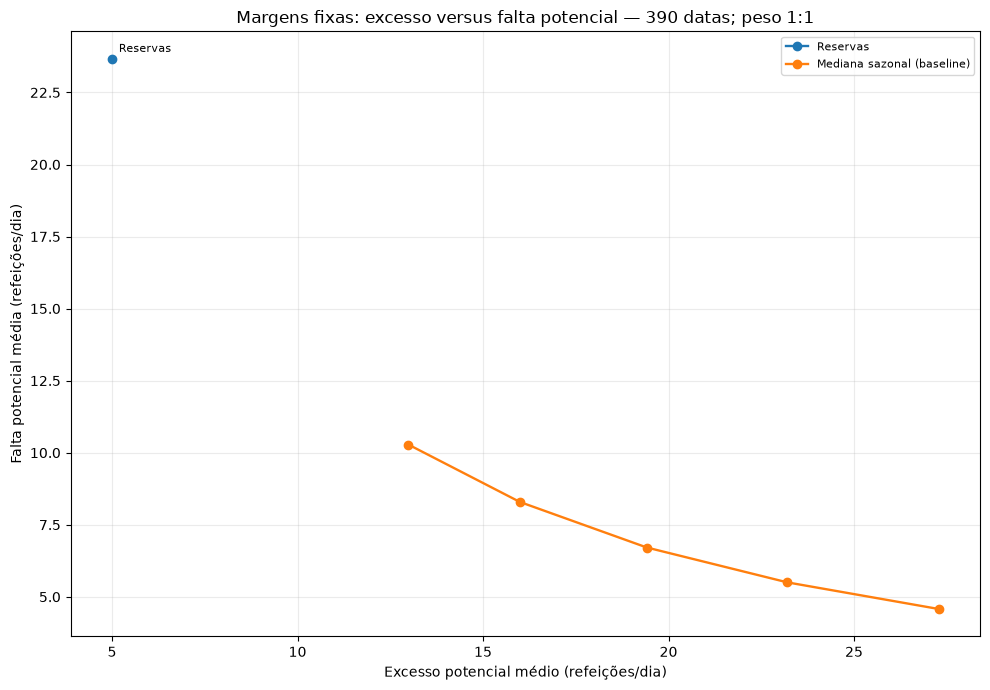

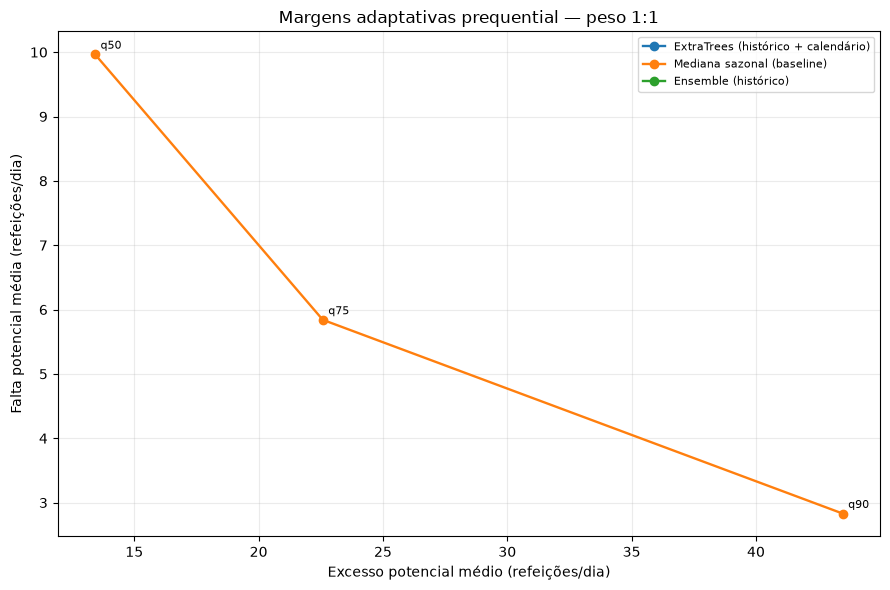

Gráficos salvos em F:\PRODUTO_MESTRADO\resultados\linhas\reservas_consumo_cardapio_calendario_clima\09_margens_vs_reservas\tradeoff_margens_fixas.png e F:\PRODUTO_MESTRADO\resultados\linhas\reservas_consumo_cardapio_calendario_clima\09_margens_vs_reservas\tradeoff_margens_adaptativas.png.


In [4]:
# Painel resumido: políticas candidatas e reservas nas mesmas datas.
reference_methods = [
    "Baseline_Reservas::total_reservas_observado",
    "Historico_Calendario::ExtraTrees",
    "Baseline_Notebook03::mediana_ultimos_8_mesmo_dia_semana",
    "Historico::Ensemble_media_por_familia",
]
selected = overall[
    overall["metodo"].isin(reference_methods)
    & overall["razao_falta_sobra"].isin([1, 2, 5])
].copy()
display(selected[[
    "metodo", "politica_margem", "razao_falta_sobra", "MAE_plano", "WAPE_plano_pct",
    "excesso_medio_dia", "falta_media_dia", "dias_com_cobertura_pct", "perda_relativa_media_dia",
    "delta_perda_media_vs_reservas",
]].sort_values(["razao_falta_sobra", "metodo", "perda_relativa_media_dia"]).round(2))

# Gráficos separados reduzem a sobreposição entre margens fixas e quantis adaptativos.
plot_data = selected[selected["razao_falta_sobra"] == 1].copy()
labels = {
    "Baseline_Reservas::total_reservas_observado": "Reservas",
    "Historico_Calendario::ExtraTrees": "ExtraTrees (histórico + calendário)",
    "Baseline_Notebook03::mediana_ultimos_8_mesmo_dia_semana": "Mediana sazonal (baseline)",
    "Historico::Ensemble_media_por_familia": "Ensemble (histórico)",
}
fixed_order = ["reservas_sem_margem", "margem_fixa_0", "margem_fixa_5", "margem_fixa_10", "margem_fixa_15", "margem_fixa_20"]
fixed_labels = {"reservas_sem_margem": "Reservas", "margem_fixa_0": "+0", "margem_fixa_5": "+5", "margem_fixa_10": "+10", "margem_fixa_15": "+15", "margem_fixa_20": "+20"}
fig, ax = plt.subplots(figsize=(10, 7))
for method in reference_methods:
    part = plot_data[(plot_data["metodo"] == method) & plot_data["politica_margem"].isin(fixed_order)].copy()
    if part.empty:
        continue
    part["ordem_margem"] = part["politica_margem"].map({p: i for i, p in enumerate(fixed_order)})
    part = part.sort_values("ordem_margem")
    ax.plot(part["excesso_medio_dia"], part["falta_media_dia"], marker="o", linewidth=1.7, label=labels[method])
    if method in {"Baseline_Reservas::total_reservas_observado", "Historico_Calendario::ExtraTrees"}:
        for row in part.itertuples(index=False):
            label = "Reservas" if method.startswith("Baseline_Reservas") else fixed_labels[row.politica_margem]
            offset = (5, 5) if method.startswith("Baseline_Reservas") else (5, 6)
            ax.annotate(label, (row.excesso_medio_dia, row.falta_media_dia),
                        xytext=offset, textcoords="offset points", fontsize=8)
ax.set_xlabel("Excesso potencial médio (refeições/dia)")
ax.set_ylabel("Falta potencial média (refeições/dia)")
ax.set_title(f"Margens fixas: excesso versus falta potencial — {len(common_dates)} datas; peso 1:1")
ax.grid(alpha=.25)
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fixed_chart = OUT / "tradeoff_margens_fixas.png"
fig.savefig(fixed_chart, dpi=170, bbox_inches="tight")
plt.show()

dynamic_order = ["prequential_q50", "prequential_q75", "prequential_q90"]
dynamic_labels = {"prequential_q50": "q50", "prequential_q75": "q75", "prequential_q90": "q90"}
fig, ax = plt.subplots(figsize=(9, 6))
for method in reference_methods[1:]:
    part = plot_data[(plot_data["metodo"] == method) & plot_data["politica_margem"].isin(dynamic_order)].copy()
    part["ordem_margem"] = part["politica_margem"].map({p: i for i, p in enumerate(dynamic_order)})
    part = part.sort_values("ordem_margem")
    ax.plot(part["excesso_medio_dia"], part["falta_media_dia"], marker="o", linewidth=1.7, label=labels[method])
    for row in part.itertuples(index=False):
        ax.annotate(dynamic_labels[row.politica_margem], (row.excesso_medio_dia, row.falta_media_dia),
                    xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Excesso potencial médio (refeições/dia)")
ax.set_ylabel("Falta potencial média (refeições/dia)")
ax.set_title("Margens adaptativas prequential — peso 1:1")
ax.grid(alpha=.25)
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
dynamic_chart = OUT / "tradeoff_margens_adaptativas.png"
fig.savefig(dynamic_chart, dpi=170, bbox_inches="tight")
plt.show()
print(f"Gráficos salvos em {fixed_chart} e {dynamic_chart}.")


In [5]:
# Ranking exploratório das políticas para pesos hipotéticos 1:1, 2:1, 3:1 e 5:1.
leaders = overall.sort_values(["razao_falta_sobra", "perda_relativa_media_dia", "MAE_plano"]).groupby(
    "razao_falta_sobra", as_index=False, group_keys=False
).head(10)
display(leaders[[
    "razao_falta_sobra", "metodo", "politica_margem", "perda_relativa_media_dia", "MAE_plano",
    "WAPE_plano_pct", "excesso_medio_dia", "falta_media_dia", "dias_com_cobertura_pct",
    "delta_perda_media_vs_reservas",
]].round(2))

reserve_row = overall[overall["metodo"].str.startswith("Baseline_Reservas") & (overall["razao_falta_sobra"] == 1)].iloc[0]
best_fixed = overall[(overall["metodo"] != reserve_row.metodo) & (overall["politica_margem"] == "margem_fixa_10") & (overall["razao_falta_sobra"] == 1)].sort_values("perda_relativa_media_dia").iloc[0]
scenario_winners = overall[overall["metodo"] != reserve_row.metodo].sort_values(
    ["razao_falta_sobra", "perda_relativa_media_dia", "MAE_plano"]
).groupby("razao_falta_sobra", as_index=False, group_keys=False).head(1)
pt = lambda value, digits=2: f"{value:.{digits}f}".replace(".", ",")
scenario_rows = []
for ratio, winner in scenario_winners.set_index("razao_falta_sobra").iterrows():
    baseline = overall[(overall["metodo"] == reserve_row.metodo) & (overall["razao_falta_sobra"] == ratio)].iloc[0]
    scenario_rows.append(
        f"| {ratio}:1 | Reservas | — | {pt(baseline.perda_relativa_media_dia)} | {pt(baseline.excesso_medio_dia)} | {pt(baseline.falta_media_dia)} | {pt(baseline.dias_com_cobertura_pct, 1)}% |"
    )
    scenario_rows.append(
        f"| {ratio}:1 | {winner.metodo} | {winner.politica_margem} | {pt(winner.perda_relativa_media_dia)} | {pt(winner.excesso_medio_dia)} | {pt(winner.falta_media_dia)} | {pt(winner.dias_com_cobertura_pct, 1)}% |"
    )
extra = annual[(annual["metodo"] == "Historico_Calendario::ExtraTrees") & annual["politica_margem"].isin(["margem_fixa_0", "margem_fixa_10"]) ]
reserve_annual = annual[annual["metodo"].str.startswith("Baseline_Reservas")]
year_rows = []
for year in sorted(extra["ano"].unique()):
    for policy in ["reservas_sem_margem", "margem_fixa_0", "margem_fixa_10"]:
        row = reserve_annual[reserve_annual["ano"] == year].iloc[0] if policy == "reservas_sem_margem" else extra[(extra["ano"] == year) & (extra["politica_margem"] == policy)].iloc[0]
        name = "Reservas" if policy == "reservas_sem_margem" else f"ExtraTrees {policy.replace('margem_fixa_', '+')}"
        year_rows.append(f"| {year} | {name} | {int(row.n_datas)} | {pt(row.MAE_plano)} | {pt(row.excesso_medio_dia)} | {pt(row.falta_media_dia)} | {pt(row.dias_com_cobertura_pct, 1)}% |")
lines = [
    "# Relatório — margens do artefato versus reservas",
    "",
    f"A coorte contém {len(common_dates)} datas pareadas sem conflitos, iguais às do Notebook 07. Foram confrontados {len(methods)} métodos com cinco margens fixas e três margens prequential; o baseline por reservas não recebeu margem.",
    "",
    "As margens mudam a decisão de quantidade, não a previsão contínua nem seu MAE/WAPE original. Os indicadores abaixo medem excesso/falta potencial em relação ao consumo histórico; não são sobra física, desperdício nem atendimento medidos.",
    "",
    f"Baseline reservas, cenário 1:1: perda relativa média {pt(reserve_row.perda_relativa_media_dia)} unidades penalizadas/dia; excesso médio {pt(reserve_row.excesso_medio_dia)}; falta média {pt(reserve_row.falta_media_dia)}; cobertura diária {pt(reserve_row.dias_com_cobertura_pct, 1)}%.",
    f"Melhor combinação exploratória entre todos os métodos/políticas sob 1:1: {overall[(overall['razao_falta_sobra']==1)].sort_values('perda_relativa_media_dia').iloc[0]['metodo']} / {overall[(overall['razao_falta_sobra']==1)].sort_values('perda_relativa_media_dia').iloc[0]['politica_margem']}. A escolha é feita e pontuada na mesma janela, portanto não é seleção validada independente.",
    f"Melhor margem fixa +10 sob 1:1: {best_fixed.metodo}; perda média {pt(best_fixed.perda_relativa_media_dia)}, excesso médio {pt(best_fixed.excesso_medio_dia)}, falta média {pt(best_fixed.falta_media_dia)}.",
    "",
    "## Cenários de sensibilidade",
    "",
    "A tabela mostra o melhor método/margem dentro de cada peso hipotético, ao lado das reservas nas mesmas datas. A linha vencedora é selecionada e avaliada na própria coorte, então serve para explorar o trade-off, não para declarar um campeão validado.",
    "",
    "| Peso falta:sobra | Regra | Margem | Perda relativa média/dia | Excesso médio/dia | Falta média/dia | Dias cobertos |",
    "|---:|---|---:|---:|---:|---:|---:|",
    *scenario_rows,
    "",
    "## Variação anual: ExtraTrees histórico + calendário",
    "",
    "| Ano | Regra | Datas | MAE do plano | Excesso médio/dia | Falta média/dia | Dias cobertos |",
    "|---:|---|---:|---:|---:|---:|---:|",
    *year_rows,
    "",
    "## Como usar a comparação",
    "",
    "A gestão pode ler os cenários como opções de risco: margens maiores tendem a aumentar cobertura e excesso potencial, reduzindo falta potencial. Os pesos 1:1 a 5:1 são cenários hipotéticos; devem ser substituídos ou calibrados quando houver custos/consequências locais confiáveis. Não há uma margem universalmente melhor.",
    "",
    "Para medir redução real de desperdício e refeições não atendidas, ainda são necessários registros reais de produção, sobra e falta. Até lá, este resultado é retrospectivo e descritivo.",
    "",
    "Gráficos: tradeoff_margens_fixas.png e tradeoff_margens_adaptativas.png. Consulte metricas_margens_vs_reservas.csv, metricas_por_ano.csv e previsoes_decisao_pareadas.csv para resultados completos.",
]
(OUT / "RELATORIO_NOTEBOOK_09.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"Relatório salvo em {OUT / 'RELATORIO_NOTEBOOK_09.md'}.")


,razao_falta_sobra,metodo,politica_margem,perda_relativa_media_dia,MAE_plano,WAPE_plano_pct,excesso_medio_dia,falta_media_dia,dias_com_cobertura_pct,delta_perda_media_vs_reservas
112,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_0,20.66,20.66,14.96,11.06,9.60,46.41,-8.00
128,1,Atual_mais_reservas::Ensemble_top5_ponderado_v...,margem_fixa_0,20.67,20.67,14.97,11.07,9.61,46.67,-7.99
372,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_5,20.85,20.85,15.10,13.66,7.19,57.95,-7.81
500,1,Atual_mais_reservas_clima::Ensemble_top5_valid...,margem_fixa_5,20.86,20.86,15.10,13.38,7.47,56.41,-7.81
240,1,Atual_mais_reservas_clima::Ensemble_top5_valid...,margem_fixa_0,20.87,20.87,15.11,10.89,9.98,45.90,-7.80
388,1,Atual_mais_reservas::Ensemble_top5_ponderado_v...,margem_fixa_5,20.87,20.87,15.11,13.67,7.21,57.95,-7.79
1412,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,prequential_q50,20.89,20.89,15.13,13.27,7.63,56.41,-7.77
116,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_0,20.90,20.90,15.13,11.04,9.86,47.69,-7.77
1428,1,Atual_mais_reservas::Ensemble_top5_ponderado_v...,prequential_q50,20.90,20.90,15.14,13.28,7.62,56.41,-7.76
108,1,Atual_mais_reservas::Ensemble_top3_validacao_m...,margem_fixa_0,20.92,20.92,15.15,11.46,9.46,48.21,-7.75


Relatório salvo em F:\PRODUTO_MESTRADO\resultados\linhas\reservas_consumo_cardapio_calendario_clima\09_margens_vs_reservas\RELATORIO_NOTEBOOK_09.md.


## Limites

- A amostra foi escolhida por ter reservas brutas observadas, consumo e previsões comuns; os resultados podem não generalizar para datas sem reserva, outros anos ou instituições.
- As margens adaptativas vieram do cálculo prequential do Notebook 06; esse cálculo usa resíduos anteriores e não consulta o consumo do próprio alvo. O notebook também verifica que previsão e alvo coincidem com o Notebook 07.
- Ranking de cenários é exploratório porque as opções são comparadas na mesma janela em que são ranqueadas.
- Faltam dados observados de produção, sobras e refeições não atendidas. O teste compara planos hipotéticos com consumo, não desperdício ou atendimento reais.
- O gestor decide qual compromisso entre excesso e risco de falta é aceitável; nenhuma margem é automaticamente recomendada como regra de produção.